대회 링크: https://dacon.io/competitions/open/235536/data

- 과제 : 미니 프로젝트(1)에 이어서, 데이콘의 '영화 관객수 예측 경진대회' 데이터셋에 회귀 알고리즘을 적용하기
- 조건 : 회귀 모델 1가지 이상 적용
- 분석 파일을 1) 제출 후 리더보드에서 점수 확인 2) github에 업로드하여 점수와 깃허브 링크를 과제함에 댓글로 달아주시면 됩니다.
- 점수 고득점팀 1위 조원분들께는 우수학회원 점수 가산이 있을 예정입니다.

📍11/23 (월): 세션 이후 조별로 모여 프로젝트 회의를 진행하고 프로젝트 회의 보고서 제출

📍11/30 (월): 최종 결과물(조당 1개의 깃허브 링크 및 리더보드 점수) 제출

📍12/21 (금): 프로젝트 최종 발표

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Windows 기본 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')

# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

#파일을 DataFrame으로 생성하고 객체 할당 
train_df=pd.read_csv(r'C:\Users\user\ESAA_YB\미니프로젝트1\movies_train.csv')
test_df=pd.read_csv(r"C:\Users\user\ESAA_YB\미니프로젝트1\movies_test.csv")


# **데이터 기본 구조·결측치 확인**

In [2]:
print('train shape:', train_df.shape)
print('test shape :', test_df.shape)
print('\n[test 컬럼 목록]')
print(test_df.columns.tolist())
print('\n[train 컬럼 목록]')
print(train_df.columns.tolist())

print('\n[test info]')
print(test_df.info())
print('\n[train info]')
print(train_df.info())

print('\n[test 결측치 개수 및 비율]')
null_summary = pd.DataFrame({
    'null_count': test_df.isnull().sum(),
    'null_ratio(%)': (test_df.isnull().mean() * 100).round(2),
})
print(null_summary[null_summary['null_count'] > 0])


print('\n[train 결측치 개수 및 비율]')
null_summary2 = pd.DataFrame({
    'null_count': train_df.isnull().sum(),
    'null_ratio(%)': (train_df.isnull().mean() * 100).round(2),
})
print(null_summary2[null_summary2['null_count'] > 0])

train shape: (600, 12)
test shape : (243, 11)

[test 컬럼 목록]
['title', 'distributor', 'genre', 'release_time', 'time', 'screening_rat', 'director', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']

[train 컬럼 목록]
['title', 'distributor', 'genre', 'release_time', 'time', 'screening_rat', 'director', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor', 'box_off_num']

[test info]
<class 'pandas.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           243 non-null    str    
 1   distributor     243 non-null    str    
 2   genre           243 non-null    str    
 3   release_time    243 non-null    str    
 4   time            243 non-null    int64  
 5   screening_rat   243 non-null    str    
 6   director        243 non-null    str    
 7   dir_prev_bfnum  107 non-null    float64
 8   dir_prev_num    243 non-null    int64  
 9   num_staff

# **수치형 변수 기초 통계량 비교**

In [3]:
#전처리
# 감독 (전작이 없으면 신인)
train_df['dir_prev_bfnum'] = train_df['dir_prev_bfnum'].fillna(0)
train_df['감독'] = np.where(train_df['dir_prev_num'] == 0, '신인', '경력')

test_df['dir_prev_bfnum'] = test_df['dir_prev_bfnum'].fillna(0)
test_df['감독'] = np.where(test_df['dir_prev_num'] == 0, '신인', '경력')

# 관객수 로그 (분포가 오른쪽으로 크게 치우쳐 있음)
train_df['log관객수'] = np.log10(train_df['box_off_num'])

#배급사 이름 전처리

# 1) 띄어쓰기 제거 및 '(주)' 텍스트 정리
def clean_distributor(x):
    x = str(x).strip()
    x = x.replace('(주)', '').replace('주식회사', '').strip()
    # 자주 틀리는 공통 이름 일치시키기
    if '쇼박스' in x:
        return '쇼박스'
    elif 'CJ' in x or '씨제이' in x:
        return 'CJ엔터테인먼트'
    elif '롯데' in x:
        return '롯데엔터테인먼트'
    elif 'NEW' in x or '뉴' in x:
        return 'NEW'
    return x

train_df['distributor_clean'] = train_df['distributor'].apply(clean_distributor)
test_df['distributor_clean'] = test_df['distributor'].apply(clean_distributor)

# 제작 규모 (스태프 수 기준)
train_df['규모'] = pd.cut(train_df['num_staff'], [-1, 80, 250, 900],
                  labels=['소(~80명)', '중(81~250명)', '대(251명~)'])

# 날짜
train_df['release_time'] = pd.to_datetime(train_df['release_time'])
train_df['연도'] = train_df['release_time'].dt.year
train_df['월'] = train_df['release_time'].dt.month
train_df['요일'] = train_df['release_time'].dt.day_name()

# test_df에도 동일한 전처리 적용
test_df['규모'] = pd.cut(
    test_df['num_staff'],
    [-1, 80, 250, 900],
    labels=['소(~80명)', '중(81~250명)', '대(251명~)']
)

test_df['release_time'] = pd.to_datetime(test_df['release_time'])
test_df['연도'] = test_df['release_time'].dt.year
test_df['월'] = test_df['release_time'].dt.month
test_df['요일'] = test_df['release_time'].dt.day_name()

In [4]:
num_cols = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']

print('=== [Test 원본 수치형 요약] ===')
print(
    test_df[num_cols].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
)

print('\n=== [Train 원본 수치형 요약 - 참고 비교] ===')
print(
    train_df[num_cols]
    .describe()
    .T[['count', 'mean', '50%', 'std', 'min', 'max']]
)

=== [Test 원본 수치형 요약] ===
                count           mean    50%            std   min        max
time            243.0     109.798354  104.0     124.022711  40.0     2015.0
dir_prev_bfnum  243.0  392628.140809    0.0  919702.613247   0.0  6173099.5
dir_prev_num    243.0       0.851852    0.0       1.200321   0.0        6.0
num_staff       243.0     159.316872  105.0     162.976607   0.0      776.0
num_actor       243.0       3.477366    3.0       2.111192   0.0       16.0

=== [Train 원본 수치형 요약 - 참고 비교] ===
                count           mean    50%           std   min         max
time            600.0     100.863333  100.0  1.809753e+01  45.0       180.0
dir_prev_bfnum  600.0  472699.301139    0.0  1.309474e+06   0.0  17615314.0
dir_prev_num    600.0       0.876667    0.0  1.183409e+00   0.0         5.0
num_staff       600.0     151.118333   82.5  1.656547e+02   0.0       869.0
num_actor       600.0       3.706667    3.0  2.446889e+00   0.0        25.0


# **범주형, 날짜변수 비율 확인**

In [5]:
# 2. 제작 규모(규모) 분포 비교
scale_comp = pd.DataFrame({
    'Train_건수': train_df['규모'].value_counts(dropna=False),
    'Train_비율(%)': (train_df['규모'].value_counts(normalize=True, dropna=False) * 100).round(2),
    'Test_건수': test_df['규모'].value_counts(dropna=False),
    'Test_비율(%)': (test_df['규모'].value_counts(normalize=True, dropna=False) * 100).round(2)
}).fillna(0)
scale_comp[['Train_건수', 'Test_건수']] = scale_comp[['Train_건수', 'Test_건수']].astype(int)

print('=== [1. 제작 규모(규모) 분포 비교] ===')
display(scale_comp)

# 3. 개봉 연도(연도) 분포 비교
year_comp = pd.DataFrame({
    'Train_건수': train_df['연도'].value_counts(),
    'Train_비율(%)': (train_df['연도'].value_counts(normalize=True) * 100).round(2),
    'Test_건수': test_df['연도'].value_counts(),
    'Test_비율(%)': (test_df['연도'].value_counts(normalize=True) * 100).round(2)
}).fillna(0).sort_index()
year_comp[['Train_건수', 'Test_건수']] = year_comp[['Train_건수', 'Test_건수']].astype(int)

print('\n=== [2. 개봉 연도(연도) 분포 비교] ===')
display(year_comp)

# 4. 개봉 월(월) 분포 비교
month_comp = pd.DataFrame({
    'Train_건수': train_df['월'].value_counts(),
    'Train_비율(%)': (train_df['월'].value_counts(normalize=True) * 100).round(2),
    'Test_건수': test_df['월'].value_counts(),
    'Test_비율(%)': (test_df['월'].value_counts(normalize=True) * 100).round(2)
}).fillna(0).sort_index()
month_comp[['Train_건수', 'Test_건수']] = month_comp[['Train_건수', 'Test_건수']].astype(int)

print('\n=== [3. 개봉 월(월) 분포 비교] ===')
display(month_comp)

# 5. 개봉 요일(요일) 분포 비교 (월~일 순서 정렬)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_comp = pd.DataFrame({
    'Train_건수': train_df['요일'].value_counts(),
    'Train_비율(%)': (train_df['요일'].value_counts(normalize=True) * 100).round(2),
    'Test_건수': test_df['요일'].value_counts(),
    'Test_비율(%)': (test_df['요일'].value_counts(normalize=True) * 100).round(2)
}).reindex(weekday_order).fillna(0)
weekday_comp[['Train_건수', 'Test_건수']] = weekday_comp[['Train_건수', 'Test_건수']].astype(int)

print('\n=== [4. 개봉 요일(요일) 분포 비교] ===')
display(weekday_comp)

=== [1. 제작 규모(규모) 분포 비교] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
규모,,,,
소(~80명),297,49.5,114,46.91
대(251명~),165,27.5,70,28.81
중(81~250명),138,23.0,59,24.28



=== [2. 개봉 연도(연도) 분포 비교] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
연도,,,,
2010,90,15.00,34,13.99
2011,80,13.33,37,15.23
2012,88,14.67,36,14.81
2013,95,15.83,35,14.40
2014,127,21.17,50,20.58
2015,120,20.00,51,20.99



=== [3. 개봉 월(월) 분포 비교] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
월,,,,
1,39,6.50,17,7.00
2,31,5.17,15,6.17
3,52,8.67,22,9.05
4,47,7.83,24,9.88
5,57,9.50,15,6.17
6,29,4.83,27,11.11
7,49,8.17,13,5.35
8,55,9.17,18,7.41
9,60,10.00,22,9.05



=== [4. 개봉 요일(요일) 분포 비교] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
요일,,,,
Monday,4,0.67,0,0.00
Tuesday,2,0.33,2,0.82
Wednesday,107,17.83,49,20.16
Thursday,484,80.67,191,78.60
Friday,2,0.33,0,0.00
Saturday,1,0.17,0,0.00
Sunday,0,0.00,1,0.41


In [6]:
# 1. 기본 고유값(nunique) 및 기간 요약 표
summary_df = pd.DataFrame({
    '구분': ['전체 영화 수', '영화 제목(title) 유일값', '감독(director) 유일값', '배급사(distributor_clean) 유일값', '개봉일 최소(min)', '개봉일 최대(max)'],
    'Train (600)': [
        len(train_df),
        train_df['title'].nunique(),
        train_df['director'].nunique(),
        train_df['distributor_clean'].nunique(),
        train_df['release_time'].min(),
        train_df['release_time'].max()
    ],
    'Test (243)': [
        len(test_df),
        test_df['title'].nunique(),
        test_df['director'].nunique(),
        test_df['distributor_clean'].nunique(),
        test_df['release_time'].min(),
        test_df['release_time'].max()
    ]
})
print('=== [1. 기본 요약 및 개봉일 범위 비교] ===')
display(summary_df)

# 2. 배급사 상위 15개 비교 (Train 기준 상위 15개에 대한 Test 건수 매칭)
top15_dist = train_df['distributor_clean'].value_counts().head(15).index
dist_comp = pd.DataFrame({
    'Train_건수': train_df['distributor_clean'].value_counts(),
    'Train_비율(%)': (train_df['distributor_clean'].value_counts(normalize=True) * 100).round(2),
    'Test_건수': test_df['distributor_clean'].value_counts(),
    'Test_비율(%)': (test_df['distributor_clean'].value_counts(normalize=True) * 100).round(2)
}).loc[top15_dist].fillna(0)
dist_comp[['Train_건수', 'Test_건수']] = dist_comp[['Train_건수', 'Test_건수']].astype(int)

print('\n=== [2. 배급사 상위 15개 비교 (Train 기준)] ===')
display(dist_comp)

# 3. 장르(genre) 분포 비교
genre_comp = pd.DataFrame({
    'Train_건수': train_df['genre'].value_counts(),
    'Train_비율(%)': (train_df['genre'].value_counts(normalize=True) * 100).round(2),
    'Test_건수': test_df['genre'].value_counts(),
    'Test_비율(%)': (test_df['genre'].value_counts(normalize=True) * 100).round(2)
}).fillna(0).sort_values(by='Train_건수', ascending=False)
genre_comp[['Train_건수', 'Test_건수']] = genre_comp[['Train_건수', 'Test_건수']].astype(int)

print('\n=== [3. 장르(genre) 분포 비교] ===')
display(genre_comp)

# 4. 관람등급(screening_rat) 분포 비교
rat_comp = pd.DataFrame({
    'Train_건수': train_df['screening_rat'].value_counts(),
    'Train_비율(%)': (train_df['screening_rat'].value_counts(normalize=True) * 100).round(2),
    'Test_건수': test_df['screening_rat'].value_counts(),
    'Test_비율(%)': (test_df['screening_rat'].value_counts(normalize=True) * 100).round(2)
}).fillna(0).sort_values(by='Train_건수', ascending=False)
rat_comp[['Train_건수', 'Test_건수']] = rat_comp[['Train_건수', 'Test_건수']].astype(int)

print('\n=== [4. 관람등급(screening_rat) 분포 비교] ===')
display(rat_comp)

=== [1. 기본 요약 및 개봉일 범위 비교] ===


,구분,Train (600),Test (243)
0,전체 영화 수,600,243
1,영화 제목(title) 유일값,600,243
2,감독(director) 유일값,472,220
3,배급사(distributor_clean) 유일값,161,86
4,개봉일 최소(min),2010-01-02 00:00:00,2010-01-07 00:00:00
5,개봉일 최대(max),2015-12-31 00:00:00,2015-12-17 00:00:00



=== [2. 배급사 상위 15개 비교 (Train 기준)] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
distributor_clean,,,,
CJ엔터테인먼트,60,10.00,32,13.17
롯데엔터테인먼트,52,8.67,25,10.29
NEW,38,6.33,10,4.12
마운틴픽쳐스,29,4.83,15,6.17
쇼박스,28,4.67,14,5.76
인디스토리,26,4.33,11,4.53
골든타이드픽처스,15,2.50,12,4.94
케이알씨지,14,2.33,5,2.06
시네마달,12,2.00,3,1.23



=== [3. 장르(genre) 분포 비교] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
genre,,,,
드라마,221,36.83,78,32.10
다큐멘터리,93,15.50,33,13.58
멜로/로맨스,78,13.00,39,16.05
코미디,53,8.83,23,9.47
공포,42,7.00,19,7.82
액션,28,4.67,21,8.64
느와르,27,4.50,12,4.94
애니메이션,21,3.50,8,3.29
미스터리,17,2.83,7,2.88



=== [4. 관람등급(screening_rat) 분포 비교] ===


,Train_건수,Train_비율(%),Test_건수,Test_비율(%)
screening_rat,,,,
청소년 관람불가,204,34.00,93,38.27
15세 관람가,202,33.67,73,30.04
12세 관람가,102,17.00,40,16.46
전체 관람가,92,15.33,37,15.23


# **배급사 비교**

train 전체 배급사 수: 161 개


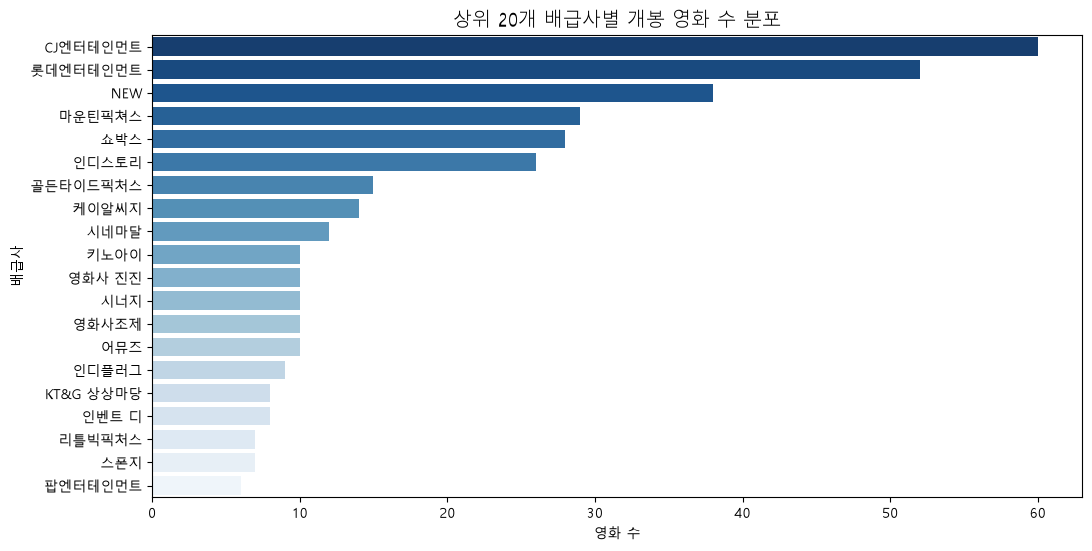

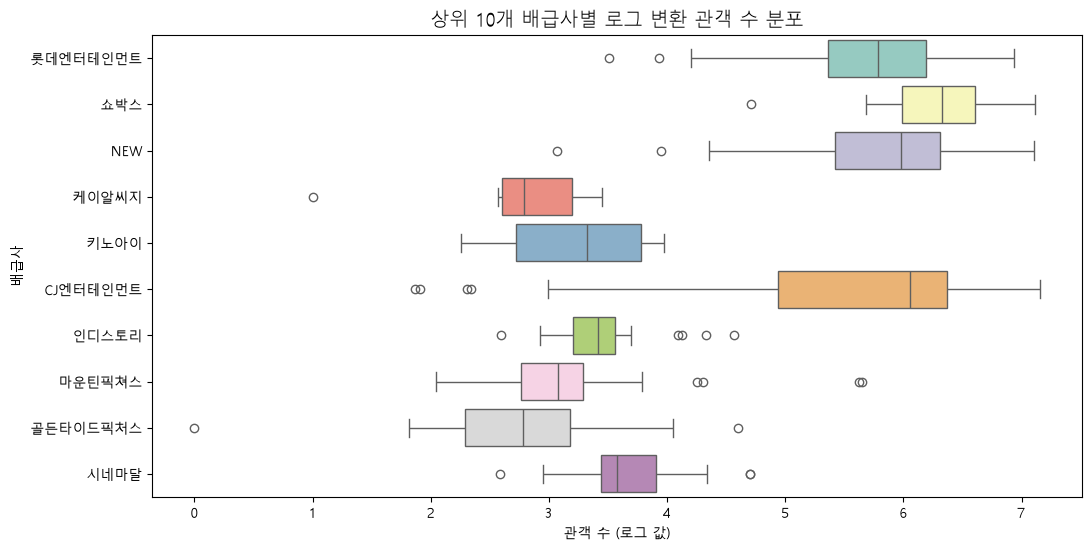

In [7]:
# 1. 전체 배급사 개수 출력
total_dist_count = train_df['distributor_clean'].nunique()
print(f"train 전체 배급사 수: {total_dist_count} 개")

# 2. 상위 20개 배급사의 영화 수 분포 시각화
plt.figure(figsize=(12, 6))
top_20_dist = train_df['distributor_clean'].value_counts().head(20)
sns.barplot(
    x=top_20_dist.values,
    y=top_20_dist.index,
    hue=top_20_dist.index,
    palette='Blues_r',
    legend=False
)
plt.title('상위 20개 배급사별 개봉 영화 수 분포', fontsize=14)
plt.xlabel('영화 수')
plt.ylabel('배급사')
plt.show()

# 3. 상위 10개 배급사의 관객 수 분포 (박스플롯)
# [17]번 셀에서 생성한 'log관객수' 컬럼 사용
top_10_names = train_df['distributor_clean'].value_counts().head(10).index
top_10_df = train_df[train_df['distributor_clean'].isin(top_10_names)]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=top_10_df,
    x='log관객수',
    y='distributor_clean',
    hue='distributor_clean',
    palette='Set3',
    legend=False
)
plt.title('상위 10개 배급사별 로그 변환 관객 수 분포', fontsize=14)
plt.xlabel('관객 수 (로그 값)')
plt.ylabel('배급사')
plt.show()

Test 전체 배급사 수: 86 개


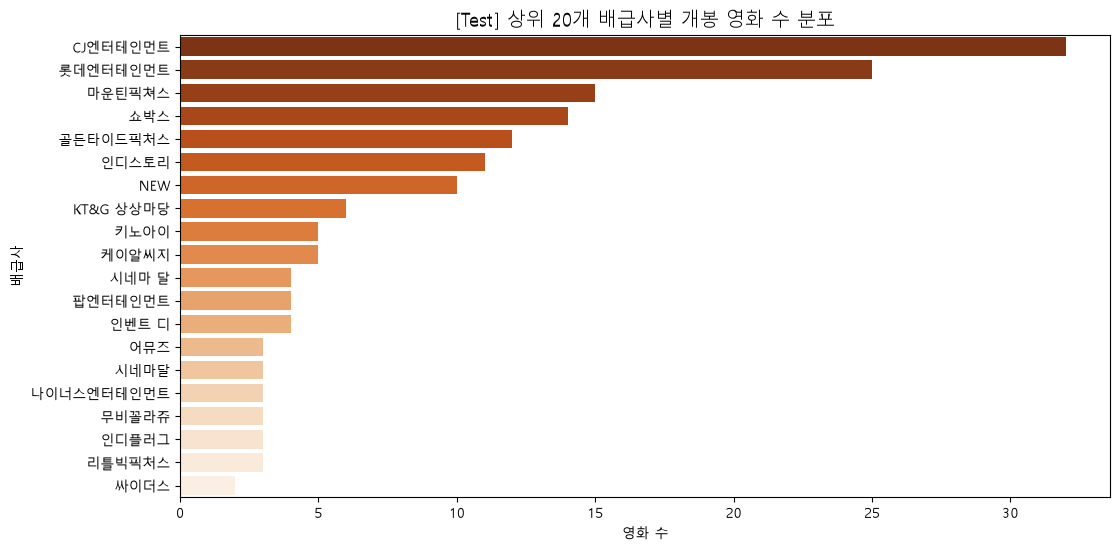

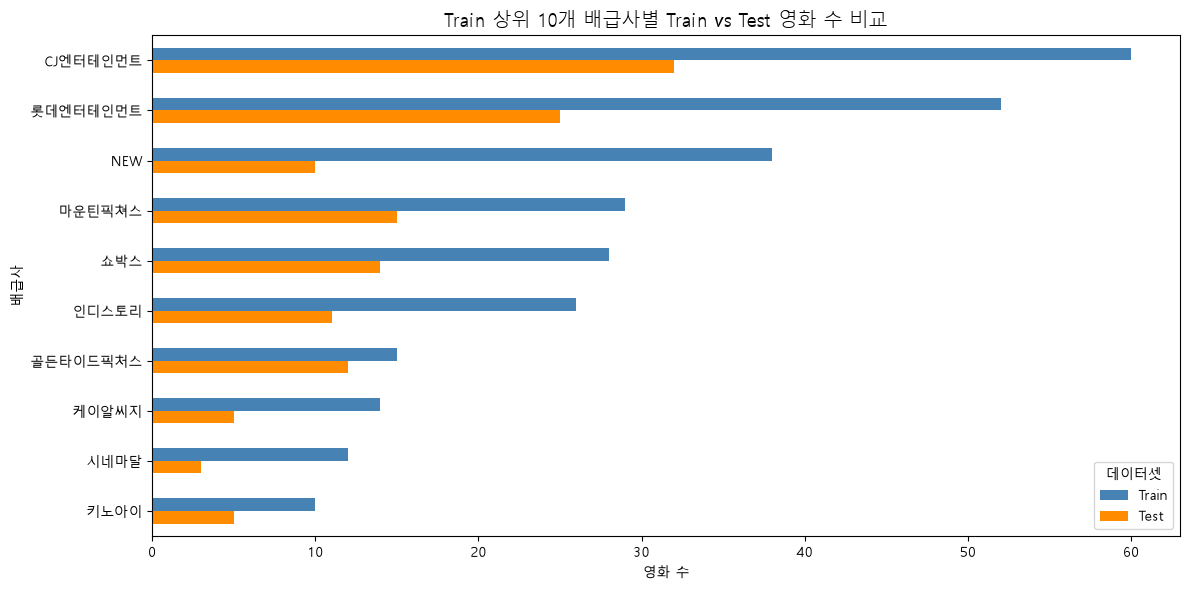

In [8]:
# 1. Test 데이터 전체 배급사 수 출력
test_dist_count = test_df['distributor_clean'].nunique()
print(f"Test 전체 배급사 수: {test_dist_count} 개")

# 2. Test 기준 상위 20개 배급사 영화 수 시각화
plt.figure(figsize=(12, 6))
top_20_test_dist = test_df['distributor_clean'].value_counts().head(20)
sns.barplot(
    x=top_20_test_dist.values,
    y=top_20_test_dist.index,
    hue=top_20_test_dist.index,
    palette='Oranges_r',
    legend=False
)
plt.title('[Test] 상위 20개 배급사별 개봉 영화 수 분포', fontsize=14)
plt.xlabel('영화 수')
plt.ylabel('배급사')
plt.show()

# 3. Train 상위 10개 배급사 기준 Train vs Test 편수 비교 (가로 막대)
top_10_names = train_df['distributor_clean'].value_counts().head(10).index
compare_top10 = pd.DataFrame({
    'Train': train_df['distributor_clean'].value_counts().reindex(top_10_names, fill_value=0),
    'Test': test_df['distributor_clean'].value_counts().reindex(top_10_names, fill_value=0)
})

compare_top10.plot(kind='barh', figsize=(12, 6), color=['steelblue', 'darkorange'])
plt.gca().invert_yaxis()
plt.title('Train 상위 10개 배급사별 Train vs Test 영화 수 비교', fontsize=14)
plt.xlabel('영화 수')
plt.ylabel('배급사')
plt.legend(title='데이터셋')
plt.tight_layout()
plt.show()

=== [Train vs Test 제작 규모 분포 비교] ===
               train_편수  train_비중(%)  test_편수  test_비중(%)
scale_group                                              
소규모 (~80명)          297         49.5      114        46.9
중규모 (81~250명)       138         23.0       59        24.3
대규모 (251명~)         165         27.5       70        28.8


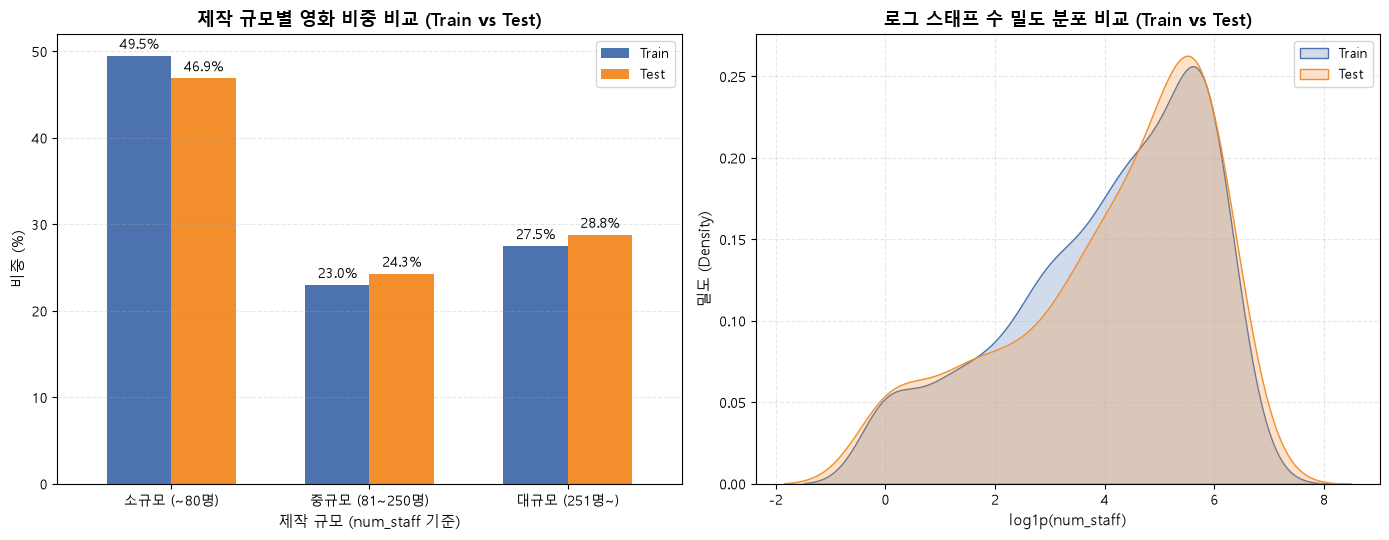

In [9]:

# 1) #5번과 동일한 기준으로 제작 규모 구간화 (train_df와 test_df 모두 적용)
bins = [-1, 80, 250, np.inf]
labels = ["소규모 (~80명)", "중규모 (81~250명)", "대규모 (251명~)"]

train_df["scale_group"] = pd.cut(
    train_df["num_staff"], bins=bins, labels=labels
)
test_df["scale_group"] = pd.cut(test_df["num_staff"], bins=bins, labels=labels)

# 2) 그룹별 편수 및 비중(%) 요약표 출력
comp_scale = pd.DataFrame({
    "train_편수": train_df["scale_group"].value_counts(sort=False),
    "train_비중(%)": (
        train_df["scale_group"].value_counts(normalize=True, sort=False) * 100
    ).round(1),
    "test_편수": test_df["scale_group"].value_counts(sort=False),
    "test_비중(%)": (
        test_df["scale_group"].value_counts(normalize=True, sort=False) * 100
    ).round(1),
})
print("=== [Train vs Test 제작 규모 분포 비교] ===")
print(comp_scale)

# 3) 시각화: 왼쪽은 규모별 비중(%) 비교, 오른쪽은 로그 스태프 수 밀도 분포 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# [왼쪽] 제작 규모 그룹별 비중(%) 막대그래프
plot_ratio = comp_scale[["train_비중(%)", "test_비중(%)"]]
plot_ratio.plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#F28E2B"], width=0.65, rot=0
)
axes[0].set_title(
    "제작 규모별 영화 비중 비교 (Train vs Test)", fontsize=13, fontweight="bold"
)
axes[0].set_ylabel("비중 (%)", fontsize=11)
axes[0].set_xlabel("제작 규모 (num_staff 기준)", fontsize=11)
axes[0].legend(["Train", "Test"])
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

for container in axes[0].containers:
  axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)

# [오른쪽] 로그 변환 스태프 수 밀도 분포 비교
sns.kdeplot(
    np.log1p(train_df["num_staff"]),
    label="Train",
    fill=True,
    ax=axes[1],
    color="#4C72B0",
)
sns.kdeplot(
    np.log1p(test_df["num_staff"]),
    label="Test",
    fill=True,
    ax=axes[1],
    color="#F28E2B",
)
axes[1].set_title(
    "로그 스태프 수 밀도 분포 비교 (Train vs Test)",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("log1p(num_staff)", fontsize=11)
axes[1].set_ylabel("밀도 (Density)", fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# **수치형변수**

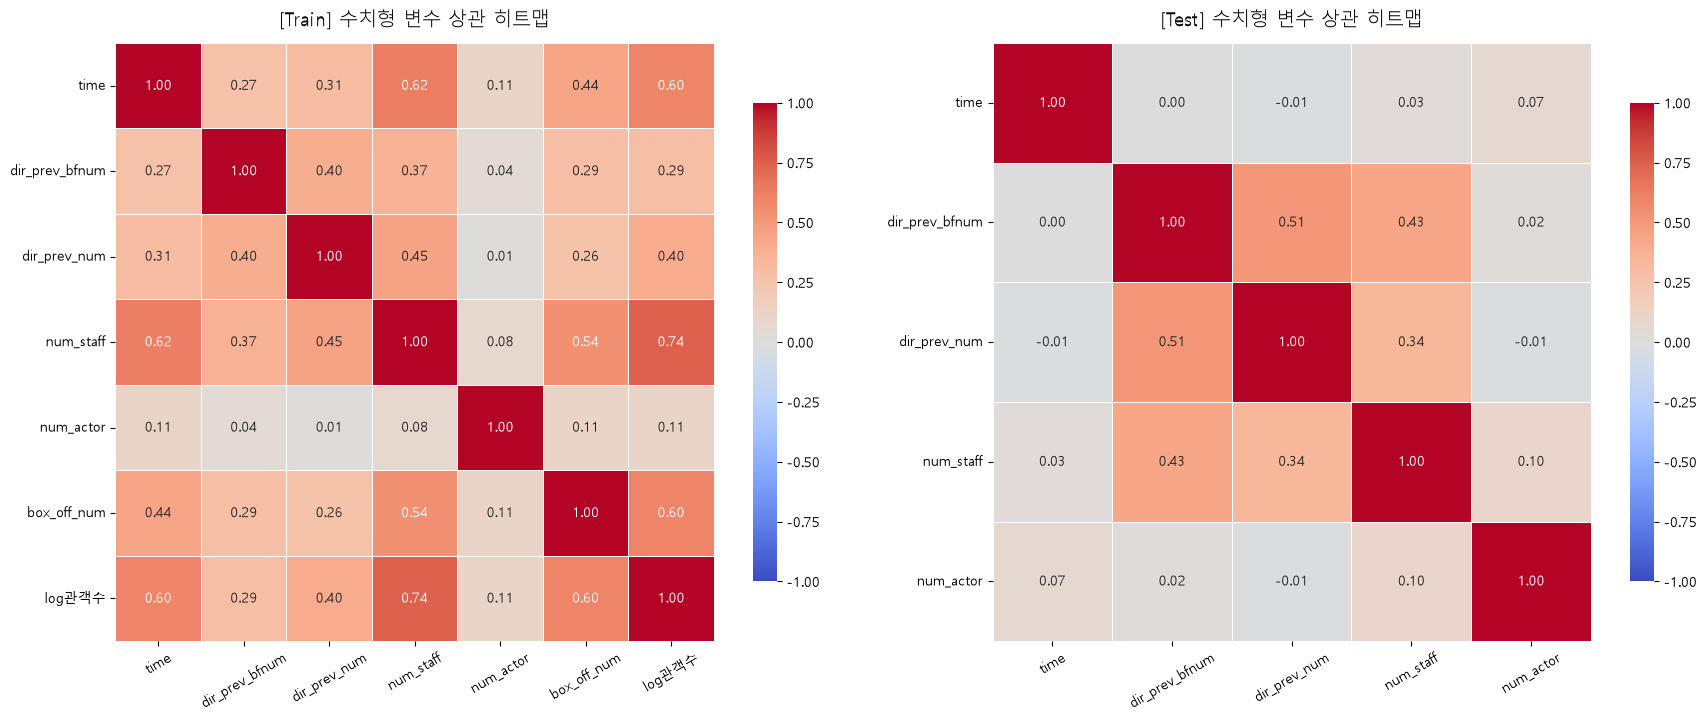

In [10]:
# 1. 수치형 컬럼 정의
base_num_cols = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']

# Train에는 타깃 변수(box_off_num, log관객수) 추가
train_target_cols = [c for c in ['box_off_num', 'log관객수'] if c in train_df.columns]
train_num_cols = base_num_cols + train_target_cols
test_num_cols = base_num_cols

# 2. 상관계수 행렬 계산 (결측치 제외 numeric_only=True)
train_corr = train_df[train_num_cols].corr(numeric_only=True)
test_corr = test_df[test_num_cols].corr(numeric_only=True)

# 3. 히트맵 나란히 시각화 (1행 2열)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# [좌] Train 상관 히트맵
sns.heatmap(
    train_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=axes[0]
)
axes[0].set_title('[Train] 수치형 변수 상관 히트맵', fontsize=14, pad=12)
axes[0].tick_params(axis='x', rotation=30)
axes[0].tick_params(axis='y', rotation=0)

# [우] Test 상관 히트맵
sns.heatmap(
    test_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=axes[1]
)
axes[1].set_title('[Test] 수치형 변수 상관 히트맵', fontsize=14, pad=12)
axes[1].tick_params(axis='x', rotation=30)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

차이) test에서 상관이 떨어진 변수들  
time과 num_staff: Train 0.62, Test 0.03  
time과 dir_prev_bfnum: Train 0.27 vs Test 0.00   
time과 dir_prev_num: Train 0.31 vs Test -0.01  

유지)  
dir_prev_num과 dir_prev_bfnum : Train 0.40 vs Test 0.51 -> 애초에 두 변수가 연관이 있어서 당연한 결과   
dir_prev_num과 num_staff : Train 0.45 vs Test 0.34   

In [11]:
# 1. Test의 time 이상치/극단치 및 상위 값 확인
print("=== [Test time 상위 10개] ===")
print(test_df[['title', 'genre', 'time', 'num_staff']].sort_values(by='time', ascending=False).head(10))

# 2. Train의 log관객수 기준 피어슨 vs 스피어만 상관계수 비교
num_for_target = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor', 'box_off_num', 'log관객수']
corr_compare = pd.DataFrame({
    'pearson_log관객수': train_df[num_for_target].corr(method='pearson')['log관객수'],
    'spearman_log관객수': train_df[num_for_target].corr(method='spearman')['log관객수'],
    'pearson_box_off_num': train_df[num_for_target].corr(method='pearson')['box_off_num']
}).round(3)

print("\n=== [Train 관객수(로그/원본) 상관계수 비교] ===")
display(corr_compare)

# 3. 0값 비율 확인 (결측/미입력 가능성 점검)
zero_check = pd.DataFrame({
    'Train_0비율(%)': ((train_df[['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']] == 0).mean() * 100).round(2),
    'Test_0비율(%)': ((test_df[['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']] == 0).mean() * 100).round(2)
})
print("\n=== [수치형 변수 내 0값 비율(%)] ===")
display(zero_check)

=== [Test time 상위 10개] ===
          title  genre  time  num_staff
224    슈퍼레이서 엔지  애니메이션  2015          4
33       카페 느와르    드라마   198        230
70          글러브    드라마   144        403
135         용의자     액션   137        376
179  군도: 민란의 시대     액션   137        685
141   마이 리틀 히어로    드라마   135        303
210      혜경궁 홍씨    드라마   134          0
108         신세계    느와르   134        361
212          간신    드라마   131        510
206        연평해전    드라마   130        437

=== [Train 관객수(로그/원본) 상관계수 비교] ===


,pearson_log관객수,spearman_log관객수,pearson_box_off_num
time,0.597,0.609,0.441
dir_prev_bfnum,0.292,0.448,0.294
dir_prev_num,0.404,0.395,0.260
num_staff,0.744,0.695,0.544
num_actor,0.112,0.127,0.111
box_off_num,0.597,1.000,1.000
log관객수,1.000,1.000,0.597



=== [수치형 변수 내 0값 비율(%)] ===


,Train_0비율(%),Test_0비율(%)
time,0.00,0.00
dir_prev_bfnum,55.00,55.97
dir_prev_num,55.00,55.97
num_staff,5.33,6.17
num_actor,1.50,1.65


1. Test time 상위 10개 이상치 점검
슈퍼레이서 엔지 (time=2015, num_staff=4): 상영시간이 2015분일 리가 없고 제작연도(2015) 오입력·특수값으로 보임. Test에서 time과 다른 변수의 상관계수가 크게 떨어진 핵심 원인 중 하나로 추정됨.

장편인데 num_staff=0인 사례(혜경궁 홍씨, time=134): 상영시간이 길어도 스태프 수가 0으로 찍힌 행이 있어 time–num_staff 선형 상관 약화에 영향을 줌.

2. Train 관객수 상관계수(피어슨 vs 스피어만) 해석
num_staff와 time이 핵심 변수: log관객수 기준 피어슨 상관계수는 num_staff (0.744), time (0.597) 순으로 높음.

dir_prev_bfnum의 피어슨(0.292) vs 스피어만(0.448) 격차:
스피어만 상관계수가 0.156이나 높게 나온다는 것은 전작 흥행 순위/서열과 관객수 순위 간 단조 증가 관계가 선형 상관보다 뚜렷하다는 뜻. 일부 초대형 흥행작(max=17,615,314)의 극단치 때문에 선형(pearson) 상관이 눌려 보이므로, dir_prev_bfnum은 로그 변환(np.log1p)을 적용하면 선형 모델에서 신호를 더 잘 잡을 수 있음.

num_actor 상관계수 낮음(0.112): 배우 수 자체로는 흥행 설명력이 약함. 인지도·이력이나 배급사·제작 규모·개봉 시기 등 다른 요인 결합이 필요함.



## **time, staff, actor 변수의 0값, 이상치 확인**

- 위에서 time의 이상치, staff와 actor 변수에서 0값이 존재하는 것을 확인.

In [12]:
# 1. Test에서 time이 200 초과인 행 확인
print("=== [Test time > 200 행] ===")
display(test_df[test_df['time'] > 200][['title', 'genre', 'release_time', 'time', 'num_staff', 'num_actor']])

# 2. Train / Test에서 num_staff == 0 또는 num_actor == 0인 행 개수 및 샘플 확인
print("\n=== [0값 행 개수 요약] ===")
print("Train num_staff == 0:", (train_df['num_staff'] == 0).sum(),
      "| Test num_staff == 0:", (test_df['num_staff'] == 0).sum())
print("Train num_actor == 0:", (train_df['num_actor'] == 0).sum(),
      "| Test num_actor == 0:", (test_df['num_actor'] == 0).sum())

print("\n=== [Test num_staff == 0 샘플 10개] ===")
display(test_df[test_df['num_staff'] == 0][['title', 'genre', 'time', 'num_staff', 'num_actor']].head(10))

print("\n=== [Test num_actor == 0 샘플 10개] ===")
display(test_df[test_df['num_actor'] == 0][['title', 'genre', 'time', 'num_staff', 'num_actor']].head(10))

=== [Test time > 200 행] ===


,title,genre,release_time,time,num_staff,num_actor
224,슈퍼레이서 엔지,애니메이션,2015-09-10,2015,4,5



=== [0값 행 개수 요약] ===
Train num_staff == 0: 32 | Test num_staff == 0: 15
Train num_actor == 0: 9 | Test num_actor == 0: 4

=== [Test num_staff == 0 샘플 10개] ===


,title,genre,time,num_staff,num_actor
19,마법천자문: 대마왕의 부활을 막아라,애니메이션,85,0,10
72,잔혹한 앵글의 로망스,미스터리,68,0,2
84,맥코리아,다큐멘터리,77,0,2
87,투 올드 힙합 키드,다큐멘터리,97,0,5
127,노라노,다큐멘터리,93,0,2
130,댄서김의 은밀한 교수법,미스터리,50,0,1
136,미녀전쟁,코미디,81,0,4
144,나가요 미스콜,멜로/로맨스,104,0,5
170,레쓰링,코미디,85,0,3
185,신화 라이브 3D 더 레전드 컨티뉴스,뮤지컬,90,0,1



=== [Test num_actor == 0 샘플 10개] ===


,title,genre,time,num_staff,num_actor
31,용서,다큐멘터리,93,1,0
94,"안녕, 하세요!",다큐멘터리,91,3,0
109,굿바이 홈런,다큐멘터리,84,3,0
164,카토 프로젝트,다큐멘터리,69,12,0


- time의 이상치 한 개 처리:
NaN 처리 후 중앙값 대체(가장 깔끔하고 무난함): 비정상 값(time > 200 등)을 결측치(np.nan)로 바꾼 뒤 train_df 기준 중앙값(median, 약 100분)으로 채우는 방식임. 2015라는 엉뚱한 숫자를 실제 상영시간처럼 취급하지 않게 막아줌.

- 학습 데이터에서 num_staff == 0이거나 num_actor == 0인 영화들의 box_off_num 및 log관객수 기초통계량, 전체 데이터와의 비교, 그리고 분포 시각화를 확인
- num_staff == 0 / num_actor == 0 관객수 통계 및 분포 코드 in train_df

=== [1. num_staff / num_actor 0값 여부별 관객수 요약 통계] ===


,그룹,편수,비율(%),관객수_평균,관객수_중앙값,관객수_최대,log관객수_평균,log관객수_중앙값,log관객수_표준편차
0,전체 (All),600,100.00,708181.8,12591.0,14262766,4.321,4.100,1.443
1,정상 (staff>0 & actor>0),560,93.33,758249.4,15891.5,14262766,4.409,4.201,1.430
2,스태프 0 (num_staff == 0),32,5.33,7805.6,996.5,72052,3.102,2.997,1.038
3,배우 0 (num_actor == 0),9,1.50,4498.2,862.0,21576,3.033,2.936,0.875
4,둘 중 하나 이상 0 (OR),40,6.67,7235.0,996.5,72052,3.091,2.997,1.007
5,둘 다 0 (AND),1,0.17,862.0,862.0,862,2.936,2.936,NaN



=== [2. num_staff == 0 또는 num_actor == 0 영화 목록] ===


,title,genre,distributor_clean,time,num_staff,num_actor,box_off_num,log관객수
580,정글히어로,애니메이션,CJ엔터테인먼트,82,0,6,72052,4.857646
290,훈장과 악동들,다큐멘터리,어뮤즈,92,0,1,39916,4.601147
394,인피니트 콘서트 세컨드 인베이전 에볼루션 더 무비 3D,다큐멘터리,골든타이드픽처스,98,0,1,39577,4.597443
526,고스트 메신저 극장판,애니메이션,에이원 엔터테인먼트,78,0,5,23802,4.376613
437,나쁜 나라,다큐멘터리,시네마달,120,2,0,21576,4.333971
339,바보야,다큐멘터리,마운틴픽쳐스,73,0,2,17912,4.253144
167,모래가 흐르는 강,다큐멘터리,시네마 달,75,11,0,10942,4.039097
173,법정스님의 의자,다큐멘터리,키노아이,75,0,2,9438,3.974880
75,원 오브 어 카인드 3D,뮤지컬,골든타이드픽처스,93,0,1,8083,3.907573
191,꾸루꾸루와 친구들: 무지개 나무의 비밀,애니메이션,팝엔터테인먼트,74,0,4,7408,3.869701


C:\Users\user\AppData\Local\Temp\ipykernel_18716\628151377.py:65: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


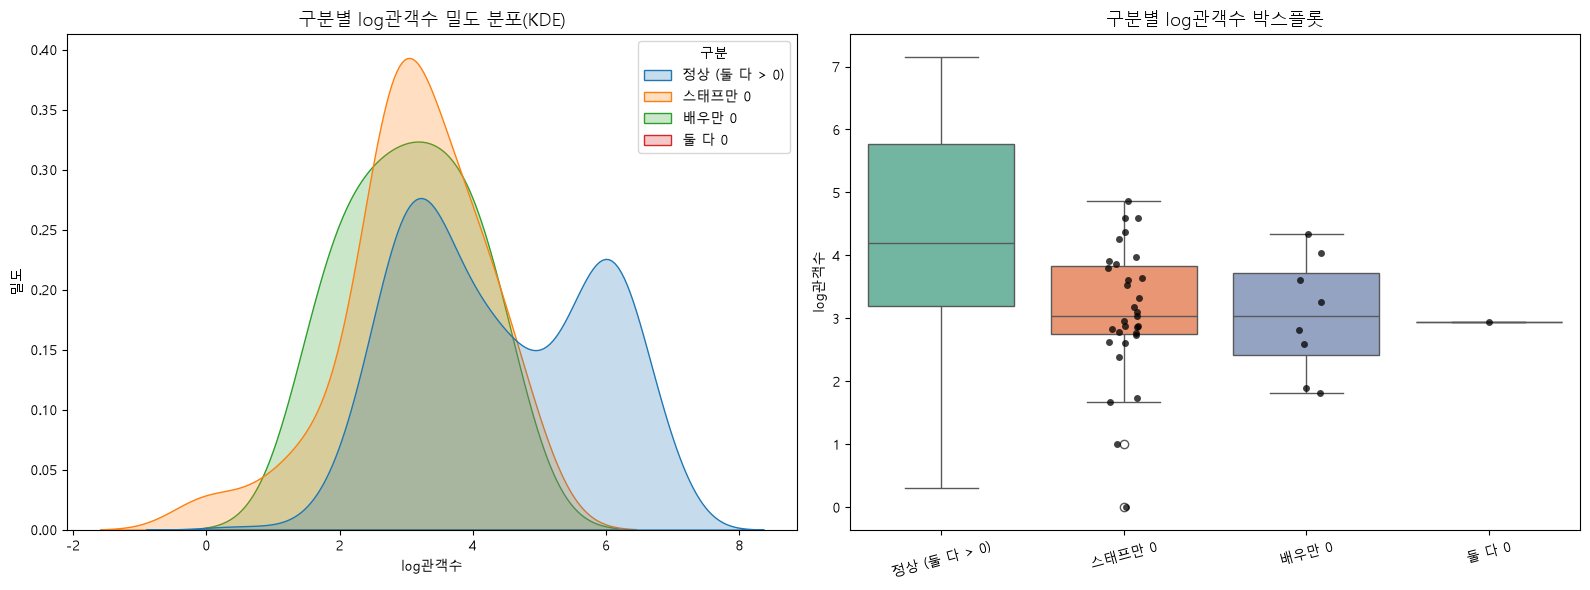

In [13]:

# log관객수 컬럼이 없으면 안전하게 생성
df_viz = train_df.copy()
if 'log관객수' not in df_viz.columns:
    df_viz['log관객수'] = np.log1p(df_viz['box_off_num'].clip(lower=0))

# 조건별 그룹 마스크 정의
cond_staff_zero = df_viz['num_staff'] == 0
cond_actor_zero = df_viz['num_actor'] == 0
cond_either_zero = cond_staff_zero | cond_actor_zero
cond_both_zero = cond_staff_zero & cond_actor_zero
cond_normal = ~cond_either_zero

groups = {
    '전체 (All)': df_viz,
    '정상 (staff>0 & actor>0)': df_viz[cond_normal],
    '스태프 0 (num_staff == 0)': df_viz[cond_staff_zero],
    '배우 0 (num_actor == 0)': df_viz[cond_actor_zero],
    '둘 중 하나 이상 0 (OR)': df_viz[cond_either_zero],
    '둘 다 0 (AND)': df_viz[cond_both_zero],
}

# 1. 그룹별 box_off_num 및 log관객수 요약 통계표
summary_rows = []
for name, sub in groups.items():
    cnt = len(sub)
    if cnt > 0:
        summary_rows.append({
            '그룹': name,
            '편수': cnt,
            '비율(%)': round(cnt / len(df_viz) * 100, 2),
            '관객수_평균': round(sub['box_off_num'].mean(), 1),
            '관객수_중앙값': round(sub['box_off_num'].median(), 1),
            '관객수_최대': int(sub['box_off_num'].max()),
            'log관객수_평균': round(sub['log관객수'].mean(), 3),
            'log관객수_중앙값': round(sub['log관객수'].median(), 3),
            'log관객수_표준편차': round(sub['log관객수'].std(), 3),
        })
    else:
        summary_rows.append({
            '그룹': name, '편수': 0, '비율(%)': 0.0,
            '관객수_평균': np.nan, '관객수_중앙값': np.nan, '관객수_최대': np.nan,
            'log관객수_평균': np.nan, 'log관객수_중앙값': np.nan, 'log관객수_표준편차': np.nan
        })

stats_zero_df = pd.DataFrame(summary_rows)
print("=== [1. num_staff / num_actor 0값 여부별 관객수 요약 통계] ===")
display(stats_zero_df)

# 2. 둘 중 하나 이상 0인 영화 상세 목록 확인
print("\n=== [2. num_staff == 0 또는 num_actor == 0 영화 목록] ===")
cols_to_show = [c for c in ['title', 'genre', 'distributor_clean', 'time', 'num_staff', 'num_actor', 'box_off_num', 'log관객수'] if c in df_viz.columns]
display(df_viz[cond_either_zero][cols_to_show].sort_values(by='box_off_num', ascending=False))

# 3. 분포 시각화 (히스토그램/KDE + 박스플롯)
plot_df = df_viz.copy()
plot_df['구분'] = np.select(
    [cond_both_zero, cond_staff_zero, cond_actor_zero],
    ['둘 다 0', '스태프만 0', '배우만 0'],
    default='정상 (둘 다 > 0)'
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# [좌] log관객수 분포 비교 (KDE + 히스토그램)
sns.kdeplot(
    data=plot_df,
    x='log관객수',
    hue='구분',
    common_norm=False,
    fill=True,
    alpha=0.25,
    ax=axes[0]
)
axes[0].set_title('구분별 log관객수 밀도 분포(KDE)', fontsize=13)
axes[0].set_xlabel('log관객수')
axes[0].set_ylabel('밀도')

# [우] 구분별 log관객수 박스플롯 & 개별 데이터 포인트
sns.boxplot(
    data=plot_df,
    x='구분',
    y='log관객수',
    hue='구분',
    palette='Set2',
    legend=False,
    ax=axes[1]
)
sns.stripplot(
    data=plot_df[plot_df['구분'] != '정상 (둘 다 > 0)'],
    x='구분',
    y='log관객수',
    color='black',
    size=5,
    alpha=0.75,
    ax=axes[1]
)
axes[1].set_title('구분별 log관객수 박스플롯', fontsize=13)
axes[1].set_xlabel('')
axes[1].set_ylabel('log관객수')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

- train_df에서 num_staff == 0 및 num_actor == 0 처리 방식(원본 유지, 0 여부 이진 플래그 추가, 0을 NaN으로 대체, 둘 다 적용)에 따른 5-Fold 교차검증(CV) RMSE 차이를 비교

In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

# 1. 타깃 변수 준비 (기존 log관객수 컬럼 우선 사용, 없으면 생성)
base_df = train_df.copy()
if 'log관객수' in base_df.columns:
    target_col = 'log관객수'
else:
    base_df['log관객수'] = np.log10(base_df['box_off_num'].clip(lower=0) + 1)
    target_col = 'log관객수'

y = base_df[target_col].values

# 기본 피처 후보 (존재하는 컬럼만 안전하게 선택)
candidate_num = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']
candidate_cat = ['genre', 'distributor_clean', 'screening_rat', '연도', '월', '요일', '규모']

num_cols = [c for c in candidate_num if c in base_df.columns]
cat_cols = [c for c in candidate_cat if c in base_df.columns]

# 2. 실험 시나리오별 데이터셋 생성 함수
def make_variant(df_in, mode):
    d = df_in[num_cols + cat_cols].copy()
    
    # 범주형 컬럼은 문자열로 통일 (결측/카테고리 혼합 방지)
    for c in cat_cols:
        d[c] = d[c].astype(str)
        
    # 0값 여부 이진 플래그 생성
    if mode in ['flag_only', 'flag_and_nan']:
        if 'num_staff' in d.columns:
            d['is_staff_zero'] = (df_in['num_staff'] == 0).astype(int)
        if 'num_actor' in d.columns:
            d['is_actor_zero'] = (df_in['num_actor'] == 0).astype(int)
            
    # 0값을 NaN으로 대체
    if mode in ['nan_only', 'flag_and_nan']:
        for col in ['num_staff', 'num_actor']:
            if col in d.columns:
                d[col] = d[col].replace(0, np.nan)
                
    return d

# 3. 전처리 + 모델 파이프라인 생성 함수
def build_pipeline(X_sample):
    curr_num = [c for c in X_sample.columns if c not in cat_cols]
    curr_cat = [c for c in X_sample.columns if c in cat_cols]
    
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer([
        ('num', num_pipe, curr_num),
        ('cat', cat_pipe, curr_cat)
    ])
    
    model = HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_depth=6,
        min_samples_leaf=20,
        random_state=42
    )
    
    return Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

# 4. 5-Fold 교차검증 실행
kf = KFold(n_splits=5, shuffle=True, random_state=42)
modes = {
    'baseline (원본 유지)': 'baseline',
    'flag_only (0 여부 플래그 추가)': 'flag_only',
    'nan_only (0 -> NaN 대체)': 'nan_only',
    'flag_and_nan (플래그 + NaN 대체)': 'flag_and_nan',
}

results = []
for label, mode in modes.items():
    X_var = make_variant(base_df, mode)
    fold_rmses = []
    
    for tr_idx, va_idx in kf.split(X_var):
        X_tr, X_va = X_var.iloc[tr_idx], X_var.iloc[va_idx]
        y_tr, y_va = y[tr_idx], y[va_idx]
        
        pipe = build_pipeline(X_var)
        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_va)
        
        fold_rmses.append(root_mean_squared_error(y_va, preds))
        
    results.append({
        '실험_조건': label,
        'CV_RMSE_평균': round(np.mean(fold_rmses), 5),
        'CV_RMSE_표준편차': round(np.std(fold_rmses), 5),
        'Fold_별_RMSE': [round(r, 4) for r in fold_rmses]
    })

cv_comp_df = pd.DataFrame(results)
base_rmse = cv_comp_df.loc[cv_comp_df['실험_조건'] == 'baseline (원본 유지)', 'CV_RMSE_평균'].iloc[0]
cv_comp_df['baseline_대비_차이'] = (cv_comp_df['CV_RMSE_평균'] - base_rmse).round(5)

print("=== [num_staff / num_actor 0값 처리별 5-Fold CV RMSE 비교 (로그 관객수 기준)] ===")
display(cv_comp_df)

=== [num_staff / num_actor 0값 처리별 5-Fold CV RMSE 비교 (로그 관객수 기준)] ===


,실험_조건,CV_RMSE_평균,CV_RMSE_표준편차,Fold_별_RMSE,baseline_대비_차이
0,baseline (원본 유지),0.82602,0.05288,"[0.8619, 0.8448, 0.7278, 0.8774, 0.8182]",0.00000
1,flag_only (0 여부 플래그 추가),0.82602,0.05288,"[0.8619, 0.8448, 0.7278, 0.8774, 0.8182]",0.00000
2,nan_only (0 -> NaN 대체),0.83286,0.05099,"[0.8621, 0.8502, 0.7488, 0.8968, 0.8064]",0.00684
3,flag_and_nan (플래그 + NaN 대체),0.83424,0.04511,"[0.8547, 0.8598, 0.7588, 0.8876, 0.8104]",0.00822


In [15]:

from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

# 선택적 라이브러리(LightGBM, XGBoost) 불러오기
models_dict = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=10.0, random_state=42),
    'Lasso': Lasso(alpha=0.01, max_iter=10000, random_state=42),
    'ElasticNet': ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000, random_state=42),
    'DecisionTree': DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4, min_samples_leaf=10, random_state=42
    ),
}

try:
    from lightgbm import LGBMRegressor
    models_dict['LGBMRegressor'] = LGBMRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=-1, num_leaves=31,
        min_child_samples=15, random_state=42, verbose=-1
    )
except ImportError:
    print("참고: lightgbm 미설치로 LGBMRegressor는 건너뜀.")

try:
    from xgboost import XGBRegressor
    models_dict['XGBRegressor'] = XGBRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, random_state=42, verbosity=0
    )
except ImportError:
    print("참고: xgboost 미설치로 XGBRegressor는 건너뜀.")

# 1. 타깃 변수 준비 (노트북 [3]번 셀의 log관객수 사용, 없으면 log10 변환 생성)
base_df = train_df.copy()
if 'log관객수' not in base_df.columns:
    base_df['log관객수'] = np.log10(base_df['box_off_num'].clip(lower=0) + 1)

y = base_df['log관객수'].values

# 2. 현재 노트북에 존재하는 수치형 / 범주형 컬럼 자동 매칭
candidate_num = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']
candidate_cat = ['genre', 'distributor_clean', 'screening_rat', '감독', '연도', '월', '요일', '규모', 'scale_group']

num_cols = [c for c in candidate_num if c in base_df.columns]
cat_cols = [c for c in candidate_cat if c in base_df.columns]

def make_variant(df_in, mode):
    d = df_in[num_cols + cat_cols].copy()
    for c in cat_cols:
        d[c] = d[c].astype(str)

    if mode in ['flag_only', 'flag_and_nan']:
        if 'num_staff' in d.columns:
            d['is_staff_zero'] = (df_in['num_staff'] == 0).astype(int)
        if 'num_actor' in d.columns:
            d['is_actor_zero'] = (df_in['num_actor'] == 0).astype(int)

    if mode in ['nan_only', 'flag_and_nan']:
        for col in ['num_staff', 'num_actor']:
            if col in d.columns:
                d[col] = d[col].replace(0, np.nan)

    return d

# 3. 동일 5-Fold 분할로 모델별 x 0값 처리 방식 비교
kf = KFold(n_splits=5, shuffle=True, random_state=42)
modes = ['baseline', 'flag_only', 'nan_only', 'flag_and_nan']

records = []
for mode in modes:
    X_var = make_variant(base_df, mode)
    curr_num = [c for c in X_var.columns if c not in cat_cols]
    curr_cat = [c for c in X_var.columns if c in cat_cols]

    preprocessor = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), curr_num),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), curr_cat),
    ])

    for model_name, reg in models_dict.items():
        fold_rmses = []
        for tr_idx, va_idx in kf.split(X_var):
            pipe = Pipeline([
                ('prep', preprocessor),
                ('model', reg),
            ])
            pipe.fit(X_var.iloc[tr_idx], y[tr_idx])
            preds = pipe.predict(X_var.iloc[va_idx])
            fold_rmses.append(root_mean_squared_error(y[va_idx], preds))

        records.append({
            '모델': model_name,
            '처리방식': mode,
            'CV_RMSE': round(np.mean(fold_rmses), 5),
        })

res_df = pd.DataFrame(records)
pivot_rmse = res_df.pivot(index='모델', columns='처리방식', values='CV_RMSE')[modes]
pivot_rmse['baseline_대비_flag_only'] = (pivot_rmse['flag_only'] - pivot_rmse['baseline']).round(5)
pivot_rmse['baseline_대비_nan_only'] = (pivot_rmse['nan_only'] - pivot_rmse['baseline']).round(5)

print("=== [회귀모델별 0값 처리 방식 5-Fold CV RMSE 비교 (log관객수 기준)] ===")
display(pivot_rmse)

# 모델별 최저 CV RMSE 요약
best_summary = (
    res_df.sort_values('CV_RMSE')
    .groupby('모델', as_index=False)
    .first()
    .rename(columns={'처리방식': '최적_처리방식', 'CV_RMSE': '최저_CV_RMSE'})
    .sort_values('최저_CV_RMSE')
)
print("\n=== [모델별 최저 CV RMSE 순위] ===")
display(best_summary)

=== [회귀모델별 0값 처리 방식 5-Fold CV RMSE 비교 (log관객수 기준)] ===


처리방식,baseline,flag_only,nan_only,flag_and_nan,baseline_대비_flag_only,baseline_대비_nan_only
모델,,,,,,
DecisionTree,0.92264,0.92264,0.90365,0.90365,0.00000,-0.01899
ElasticNet,0.82089,0.82157,0.82235,0.82150,0.00068,0.00146
GradientBoosting,0.80666,0.80668,0.81729,0.81685,0.00002,0.01063
LGBMRegressor,0.82735,0.82735,0.84347,0.83404,0.00000,0.01612
Lasso,0.82851,0.82849,0.83012,0.82826,-0.00002,0.00161
LinearRegression,0.85541,0.85912,0.85700,0.85912,0.00371,0.00159
Ridge,0.81441,0.81413,0.81636,0.81412,-0.00028,0.00195
XGBRegressor,0.79116,0.79519,0.79764,0.79514,0.00403,0.00648



=== [모델별 최저 CV RMSE 순위] ===


,모델,최적_처리방식,최저_CV_RMSE
7,XGBRegressor,baseline,0.79116
2,GradientBoosting,baseline,0.80666
6,Ridge,flag_and_nan,0.81412
1,ElasticNet,baseline,0.82089
3,LGBMRegressor,baseline,0.82735
4,Lasso,flag_and_nan,0.82826
5,LinearRegression,baseline,0.85541
0,DecisionTree,nan_only,0.90365


- 5-Fold CV 결과를 보면 부스팅 계열(XGBRegressor, GradientBoosting)이 가장 좋은 성능을 냈고, 선형 규제 모델(Ridge, ElasticNet)이 그 뒤를 따랐으며, 0값 처리 방식은 대부분의 모델에서 baseline(0 원본 유지)이 유리하거나 큰 차이가 없는 쪽으로 나왔음.

적용된 time 중앙값(train 기준): 100.0
Train 보정된 time 개수: 0 | Test 보정된 time 개수: 1
정제 후 Test time 범위: 40.0 ~ 198.0


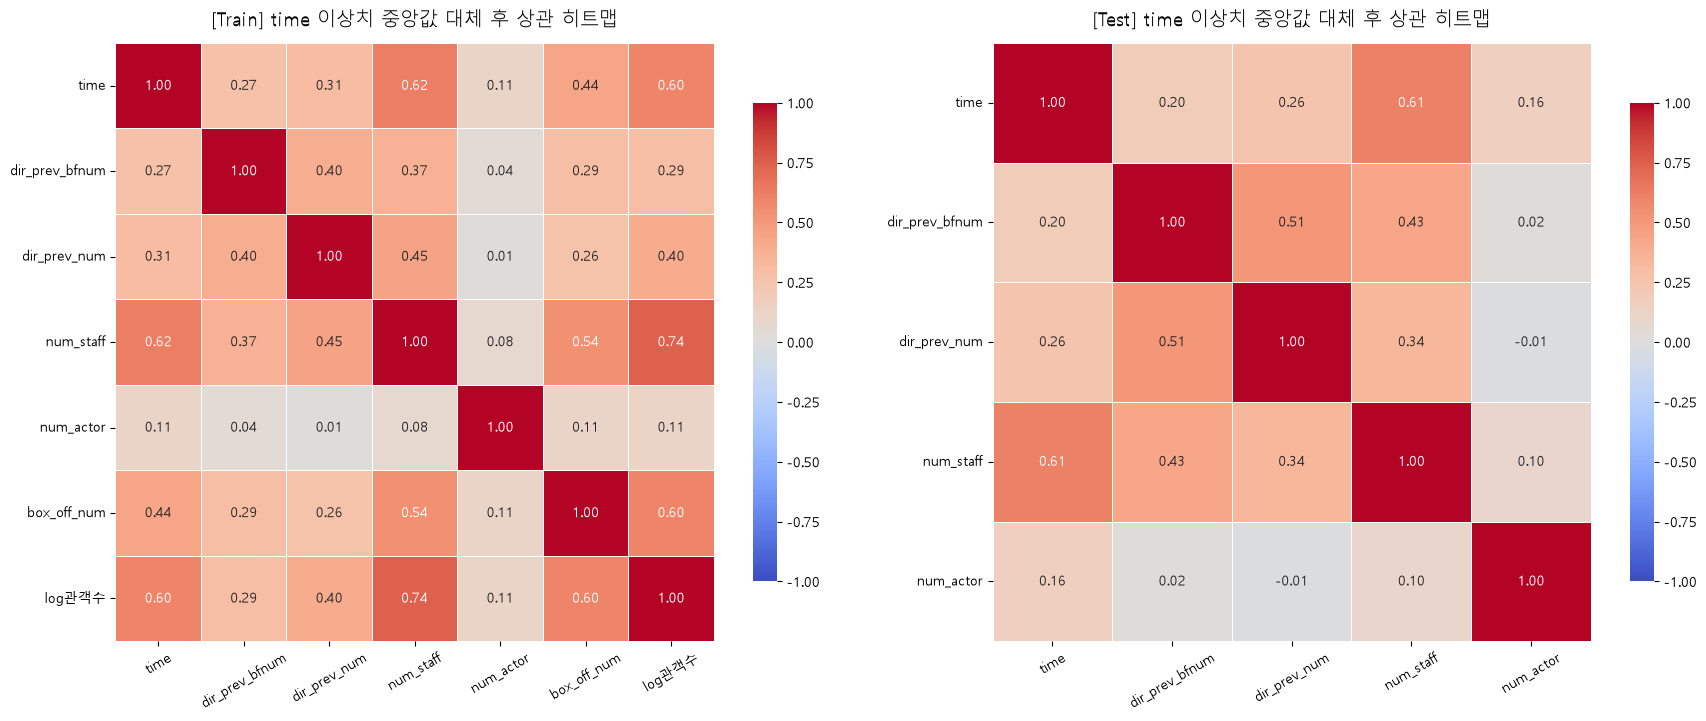

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 원본 보존용 복사본 생성 (num_staff, num_actor의 0값은 baseline 그대로 유지)
train_hm = train_df.copy()
test_hm = test_df.copy()

# log관객수 컬럼이 없으면 안전하게 생성 (노트북 [3]번 셀 기준 log10 적용)
if 'log관객수' not in train_hm.columns and 'box_off_num' in train_hm.columns:
    train_hm['log관객수'] = np.log10(train_hm['box_off_num'].clip(lower=0) + 1)

# 2. time 이상치(0 이하 또는 200 초과)를 NaN으로 만든 뒤 train_df 중앙값으로 대체
upper_bound = 200
train_time_clean = train_hm['time'].where((train_hm['time'] > 0) & (train_hm['time'] <= upper_bound), np.nan)
test_time_clean = test_hm['time'].where((test_hm['time'] > 0) & (test_hm['time'] <= upper_bound), np.nan)

time_median = train_time_clean.median()
train_hm['time'] = train_time_clean.fillna(time_median)
test_hm['time'] = test_time_clean.fillna(time_median)

print(f"적용된 time 중앙값(train 기준): {time_median}")
print(f"Train 보정된 time 개수: {train_time_clean.isna().sum()} | Test 보정된 time 개수: {test_time_clean.isna().sum()}")
print(f"정제 후 Test time 범위: {test_hm['time'].min()} ~ {test_hm['time'].max()}")

# 3. 상관행렬 계산 및 히트맵 시각화 (노트북 [10]번 셀 구조 유지)
base_num_cols = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']
train_target_cols = [c for c in ['box_off_num', 'log관객수'] if c in train_hm.columns]
train_num_cols = base_num_cols + train_target_cols
test_num_cols = base_num_cols

train_corr_clean = train_hm[train_num_cols].corr(numeric_only=True)
test_corr_clean = test_hm[test_num_cols].corr(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# [좌] Train 상관 히트맵
sns.heatmap(
    train_corr_clean,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=axes[0]
)
axes[0].set_title('[Train] time 이상치 중앙값 대체 후 상관 히트맵', fontsize=14, pad=12)
axes[0].tick_params(axis='x', rotation=30)
axes[0].tick_params(axis='y', rotation=0)

# [우] Test 상관 히트맵
sns.heatmap(
    test_corr_clean,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=axes[1]
)
axes[1].set_title('[Test] time 이상치 중앙값 대체 후 상관 히트맵', fontsize=14, pad=12)
axes[1].tick_params(axis='x', rotation=30)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

time과 num_staff: Train 0.62, Test 0.61  
time과 dir_prev_bfnum: Train 0.27 vs Test 0.2
time과 dir_prev_num: Train 0.31 vs Test 0.26

## 수치형 변수 - 분포의 치우침·꼬리(왜도/극단치), 0값 비율, 그리고 Train과 비교했을 때 Test에 새로운 범위/극단치가 있는지
-앞서 Train에서 피어슨보다 스피어만 상관이 높게 나왔듯, Test에서도 분포가 극단적으로 치우쳐 있어 로그 변환(np.log1p) 후 분포를 함께 보는 편이 좋음.

=== [Test 수치형 변수 분포·극단치 요약] ===


,skew(왜도),0_비율(%),min,25%,50%(중앙값),75%,max
time,0.32,0.00,40.0,91.0,104.0,114.000,198.0
dir_prev_bfnum,3.54,55.97,0.0,0.0,0.0,321700.375,6173099.5
dir_prev_num,1.49,55.97,0.0,0.0,0.0,1.000,6.0
num_staff,0.99,6.17,0.0,18.0,105.0,282.000,776.0
num_actor,2.00,1.65,0.0,2.0,3.0,4.000,16.0



=== [Train 최소/최대 범위를 벗어난 Test 행 점검] ===
- time (Train 범위: 45 ~ 180): Test 범위 밖 2건


,title,genre,time
33,카페 느와르,드라마,198.0
140,오하이오 삿포로,멜로/로맨스,40.0


- dir_prev_bfnum (Train 범위: 0.0 ~ 17615314.0): Test 범위 밖 0건
- dir_prev_num (Train 범위: 0 ~ 5): Test 범위 밖 1건


,title,genre,dir_prev_num
183,더 테너 리리코 스핀토,드라마,6


- num_staff (Train 범위: 0 ~ 869): Test 범위 밖 0건
- num_actor (Train 범위: 0 ~ 25): Test 범위 밖 0건


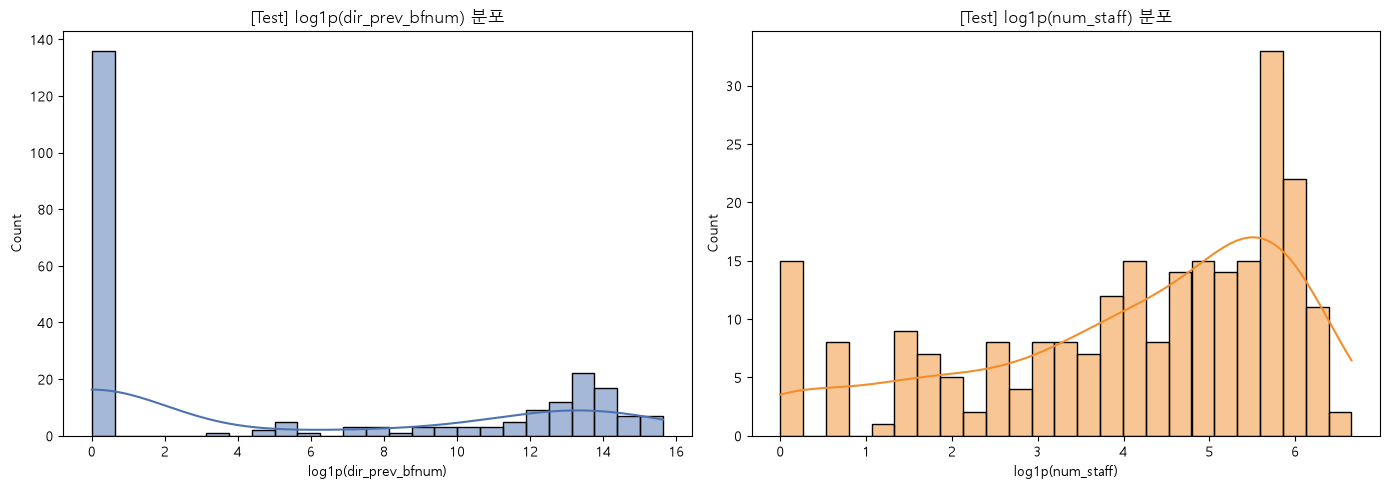

In [17]:


# [16]번 셀 기준 time 이상치 보정본이 있으면 사용, 없으면 임시 생성
if 'test_hm' in globals():
    t_df = test_hm.copy()
else:
    t_df = test_df.copy()
    train_t_clean = train_df['time'].where((train_df['time'] > 0) & (train_df['time'] <= 200), np.nan)
    test_t_clean = t_df['time'].where((t_df['time'] > 0) & (t_df['time'] <= 200), np.nan)
    t_df['time'] = test_t_clean.fillna(train_t_clean.median())

num_cols = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']

# 1. Test 수치형 변수 상세 요약 (왜도, 사분위수, 0 비율 포함)
test_dist_summary = pd.DataFrame({
    'skew(왜도)': t_df[num_cols].skew().round(2),
    '0_비율(%)': ((t_df[num_cols] == 0).mean() * 100).round(2),
    'min': t_df[num_cols].min(),
    '25%': t_df[num_cols].quantile(0.25),
    '50%(중앙값)': t_df[num_cols].median(),
    '75%': t_df[num_cols].quantile(0.75),
    'max': t_df[num_cols].max(),
})
print("=== [Test 수치형 변수 분포·극단치 요약] ===")
display(test_dist_summary)

# 2. Train 범위 밖(min 미만 또는 max 초과) Test 행 점검
print("\n=== [Train 최소/최대 범위를 벗어난 Test 행 점검] ===")
for col in num_cols:
    tr_min, tr_max = train_df[col].min(), train_df[col].max()
    out_rows = t_df[(t_df[col] < tr_min) | (t_df[col] > tr_max)]
    print(f"- {col} (Train 범위: {tr_min} ~ {tr_max}): Test 범위 밖 {len(out_rows)}건")
    if len(out_rows) > 0:
        display(out_rows[['title', 'genre', col]].head(5))

# 3. 치우침이 큰 변수(dir_prev_bfnum, num_staff) 로그 변환 분포 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(np.log1p(t_df['dir_prev_bfnum']), bins=25, kde=True, color='#4C72B0', ax=axes[0])
axes[0].set_title('[Test] log1p(dir_prev_bfnum) 분포', fontsize=12)
axes[0].set_xlabel('log1p(dir_prev_bfnum)')

sns.histplot(np.log1p(t_df['num_staff']), bins=25, kde=True, color='#F28E2B', ax=axes[1])
axes[1].set_title('[Test] log1p(num_staff) 분포', fontsize=12)
axes[1].set_xlabel('log1p(num_staff)')

plt.tight_layout()
plt.show()

# **날짜형, 범주형 변수 비교**

In [19]:

# log관객수 컬럼이 없으면 안전하게 생성 ([3]번 셀 기준 log10 적용)
tr_df = train_df.copy()
te_df = test_df.copy()

# 중복 컬럼 scale_group 제거
for d_tmp in [tr_df, te_df]:
    if 'scale_group' in d_tmp.columns:
        d_tmp.drop(columns=['scale_group'], inplace=True)

if 'log관객수' not in tr_df.columns and 'box_off_num' in tr_df.columns:
    tr_df['log관객수'] = np.log10(tr_df['box_off_num'].clip(lower=0) + 1)

# 1. 범주형/날짜파생 컬럼별 고유값 수 및 Test 내 Unseen(Train에 없는 값) 비율 확인
cat_check_cols = [
    c for c in ['genre', 'screening_rat', 'distributor_clean', 'director', '감독', '규모', '연도', '월', '요일']
    if c in tr_df.columns and c in te_df.columns
]

unseen_rows = []
for col in cat_check_cols:
    tr_set = set(tr_df[col].dropna().astype(str))
    te_vals = te_df[col].dropna().astype(str)
    unseen_mask = ~te_vals.isin(tr_set)
    unseen_rows.append({
        '컬럼': col,
        'Train_고유값수': len(tr_set),
        'Test_고유값수': te_vals.nunique(),
        'Test_Unseen_행수': int(unseen_mask.sum()),
        'Test_Unseen_비율(%)': round(unseen_mask.mean() * 100, 2),
        'Test_Unseen_고유값수': te_vals[unseen_mask].nunique(),
    })

print("=== [1. 범주형/날짜파생 컬럼 Train vs Test 미등록(Unseen) 요약] ===")
display(pd.DataFrame(unseen_rows))

# 2. 주요 범주형 변수(genre, screening_rat, 감독, 규모)별 Train/Test 비율 및 Train log관객수 요약
for col in [c for c in ['genre', 'screening_rat', '감독', '규모'] if c in tr_df.columns and c in te_df.columns]:
    tr_cnt = tr_df[col].astype(str).value_counts()
    tr_pct = (tr_df[col].astype(str).value_counts(normalize=True) * 100).round(2)
    te_cnt = te_df[col].astype(str).value_counts()
    te_pct = (te_df[col].astype(str).value_counts(normalize=True) * 100).round(2)

    stat_grp = tr_df.groupby(tr_df[col].astype(str))['log관객수'].agg(['mean', 'median']).round(3)

    comp = pd.DataFrame({
        'Train_건수': tr_cnt,
        'Train_%': tr_pct,
        'Test_건수': te_cnt,
        'Test_%': te_pct,
        'Train_log관객수_평균': stat_grp['mean'],
        'Train_log관객수_중앙값': stat_grp['median'],
    }).fillna(0)
    comp[['Train_건수', 'Test_건수']] = comp[['Train_건수', 'Test_건수']].astype(int)
    print(f"\n=== [2. '{col}' Train vs Test 분포 및 Train log관객수 요약] ===")
    display(comp.sort_values('Train_건수', ascending=False))

# 3. Test에만 등장하는 distributor_clean 샘플 확인
if 'distributor_clean' in tr_df.columns and 'distributor_clean' in te_df.columns:
    tr_dist = set(tr_df['distributor_clean'].astype(str))
    unseen_dist = te_df[~te_df['distributor_clean'].astype(str).isin(tr_dist)]['distributor_clean']
    print(f"\n=== [3. Test에만 있는 배급사(distributor_clean) {unseen_dist.nunique()}개 / {len(unseen_dist)}건] ===")
    display(unseen_dist.value_counts().head(15))

=== [1. 범주형/날짜파생 컬럼 Train vs Test 미등록(Unseen) 요약] ===


,컬럼,Train_고유값수,Test_고유값수,Test_Unseen_행수,Test_Unseen_비율(%),Test_Unseen_고유값수
0,genre,12,12,0,0.00,0
1,screening_rat,4,4,0,0.00,0
2,distributor_clean,161,86,34,13.99,32
3,director,472,220,154,63.37,142
4,감독,2,2,0,0.00,0
5,규모,3,3,0,0.00,0
6,연도,6,6,0,0.00,0
7,월,12,12,0,0.00,0
8,요일,6,4,1,0.41,1



=== [2. 'genre' Train vs Test 분포 및 Train log관객수 요약] ===


,Train_건수,Train_%,Test_건수,Test_%,Train_log관객수_평균,Train_log관객수_중앙값
genre,,,,,,
드라마,221,36.83,78,32.10,4.207,3.856
다큐멘터리,93,15.50,33,13.58,3.575,3.483
멜로/로맨스,78,13.00,39,16.05,3.981,3.562
코미디,53,8.83,23,9.47,4.972,5.324
공포,42,7.00,19,7.82,4.824,5.240
액션,28,4.67,21,8.64,5.601,6.060
느와르,27,4.50,12,4.94,5.565,6.216
애니메이션,21,3.50,8,3.29,4.368,4.377
미스터리,17,2.83,7,2.88,4.017,3.505



=== [2. 'screening_rat' Train vs Test 분포 및 Train log관객수 요약] ===


,Train_건수,Train_%,Test_건수,Test_%,Train_log관객수_평균,Train_log관객수_중앙값
screening_rat,,,,,,
청소년 관람불가,204,34.00,93,38.27,3.898,3.478
15세 관람가,202,33.67,73,30.04,4.872,5.384
12세 관람가,102,17.00,40,16.46,4.469,4.286
전체 관람가,92,15.33,37,15.23,3.884,3.920


... (2 outputs left out)


=== [2. '규모' Train vs Test 분포 및 Train log관객수 요약] ===


,Train_건수,Train_%,Test_건수,Test_%,Train_log관객수_평균,Train_log관객수_중앙값
규모,,,,,,
소(~80명),297,49.5,114,46.91,3.407,3.257
대(251명~),165,27.5,70,28.81,5.974,6.068
중(81~250명),138,23.0,59,24.28,4.310,4.249



=== [3. Test에만 있는 배급사(distributor_clean) 32개 / 34건] ===


distributor_clean
미로비젼          2
디씨드           2
모쿠슈라          1
루믹스미디어        1
노근리 프로덕션      1
리얼라이즈픽쳐스      1
청년필름          1
리아코어콘텐츠       1
핑크로봇 필름       1
Cinema SAM    1
갑종필름          1
필마픽쳐스         1
오픈유컬쳐         1
드림웨스트픽쳐스      1
명필름           1
Name: count, dtype: int64

1. Test 내 미등록(Unseen) 범주 요약
genre (12개), screening_rat (4개), 감독 (2개), 규모 (3개), 연도 (6개), 월 (12개): Train과 Test의 고유값 집합이 완전히 일치해 Unseen 비율이 0.00%임.

요일: Train 6개, Test 4개이며 Test의 Sunday(1건)가 Train에 없어 1건(0.41%)이 미등록으로 잡힘.

distributor_clean: Train 161개, Test 86개 중 Test에만 처음 나온 배급사가 32개(34건, 13.99%)임.

director: Train 472개, Test 220개 중 Test에만 등장한 감독이 142명(154건, 63.37%)으로 절반을 훌쩍 넘음.

2. 주요 범주형 변수별 흥행(log관객수)·분포 해석
genre:

드라마(Train 36.83%, Test 32.10%), 멜로/로맨스(13.00% vs 16.05%), 다큐멘터리(15.50% vs 13.58%)처럼 비중이 큰 장르의 log관객수 중앙값은 3.48~3.86 수준으로 상대적으로 낮음.

반면 느와르(중앙값 6.216), 액션(6.060), 코미디(5.324), 공포(5.240)는 흥행 수준이 높고, Test에서 액션 비중(8.64%)이 Train(4.67%)보다 약 1.85배 높게 나타남.

SF, 뮤지컬, 서스펜스는 Test에 각 1건(0.41%)씩만 있어 표본이 매우 적음.

screening_rat:

15세 관람가(Train 중앙값 5.384)와 12세 관람가(4.286)가 청소년 관람불가(3.478)나 전체 관람가(3.920)보다 흥행 수준이 높고, Test에서는 청소년 관람불가 비중(38.27%)이 Train(34.00%)보다 조금 더 높음.

감독 (신인 vs 경력):

Train과 Test의 신인(약 55~56%) vs 경력(약 44~45%) 비율이 거의 동일하고, 경력 감독의 log관객수 중앙값(5.347)이 신인(3.532)보다 크게 높아 개별 director 이름보다 파생변수 감독이 훨씬 안정적이고 유용한 신호를 줌.

규모:

소(~80명) 중앙값 3.257, 중(81~250명) 4.249, 대(251명~) 6.068로 구간별 관객수 차이가 뚜렷하며, Train과 Test의 비율 차이도 1~2%p 이내로 안정적임.

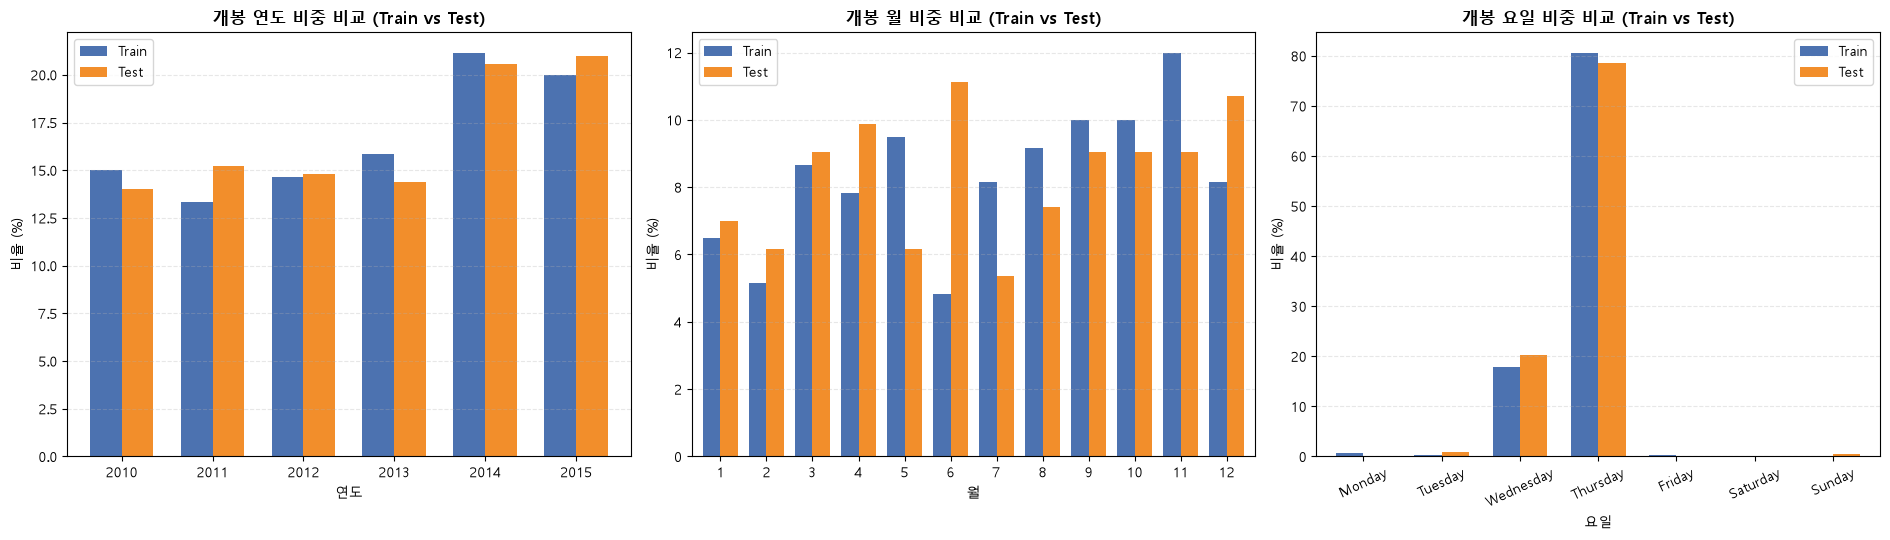

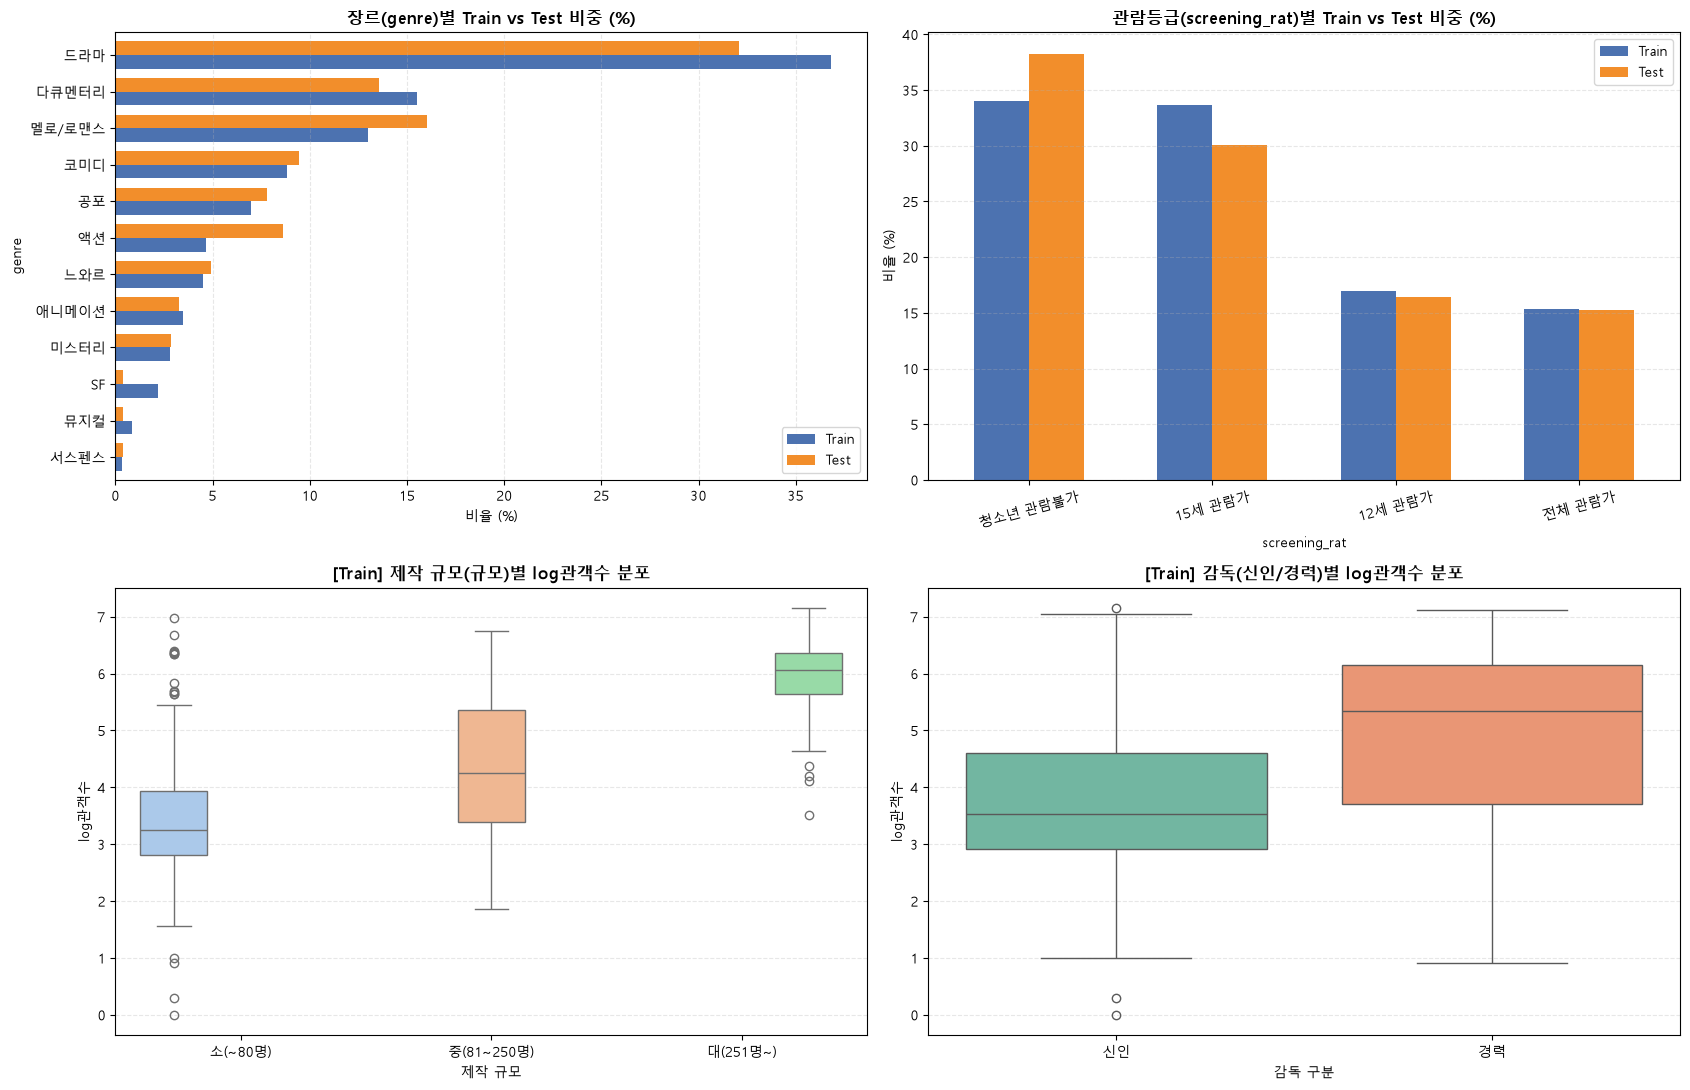

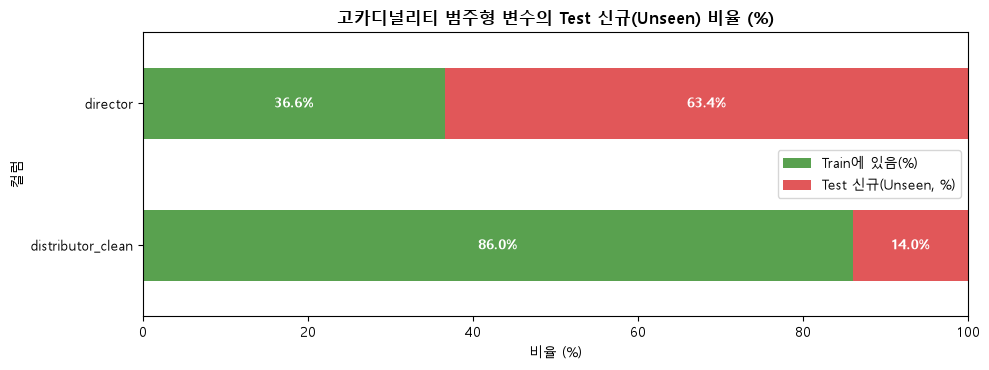

In [20]:


# 1. 전처리 상태 맞추기 ([19]번 셀 기준 scale_group 제거 및 log관객수 확보)
tr_v = train_df.copy()
te_v = test_df.copy()

for d_tmp in [tr_v, te_v]:
    if 'scale_group' in d_tmp.columns:
        d_tmp.drop(columns=['scale_group'], inplace=True)

if 'log관객수' not in tr_v.columns and 'box_off_num' in tr_v.columns:
    tr_v['log관객수'] = np.log10(tr_v['box_off_num'].clip(lower=0) + 1)

# ---------------------------------------------------------
# [그래프 1] 날짜 파생변수(연도, 월, 요일) Train vs Test 비중(%) 비교
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# (1) 연도별 비중
year_df = pd.DataFrame({
    'Train': tr_v['연도'].value_counts(normalize=True) * 100,
    'Test': te_v['연도'].value_counts(normalize=True) * 100,
}).fillna(0).sort_index()
year_df.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#F28E2B'], width=0.7, rot=0)
axes[0].set_title('개봉 연도 비중 비교 (Train vs Test)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('비율 (%)')
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

# (2) 월별 비중
month_df = pd.DataFrame({
    'Train': tr_v['월'].value_counts(normalize=True) * 100,
    'Test': te_v['월'].value_counts(normalize=True) * 100,
}).fillna(0).reindex(range(1, 13), fill_value=0)
month_df.plot(kind='bar', ax=axes[1], color=['#4C72B0', '#F28E2B'], width=0.75, rot=0)
axes[1].set_title('개봉 월 비중 비교 (Train vs Test)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('비율 (%)')
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

# (3) 요일별 비중
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
wday_df = pd.DataFrame({
    'Train': tr_v['요일'].value_counts(normalize=True) * 100,
    'Test': te_v['요일'].value_counts(normalize=True) * 100,
}).fillna(0).reindex(weekday_order, fill_value=0)
wday_df.plot(kind='bar', ax=axes[2], color=['#4C72B0', '#F28E2B'], width=0.7, rot=25)
axes[2].set_title('개봉 요일 비중 비교 (Train vs Test)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('비율 (%)')
axes[2].grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# [그래프 2] 주요 범주형 변수(장르, 관람등급, 감독, 규모) 비중 + 흥행 수준
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

# (1) 장르별 Train vs Test 비중
genre_df = pd.DataFrame({
    'Train': tr_v['genre'].value_counts(normalize=True) * 100,
    'Test': te_v['genre'].value_counts(normalize=True) * 100,
}).fillna(0).sort_values('Train', ascending=True)
genre_df.plot(kind='barh', ax=axes[0, 0], color=['#4C72B0', '#F28E2B'], width=0.75)
axes[0, 0].set_title('장르(genre)별 Train vs Test 비중 (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('비율 (%)')
axes[0, 0].grid(axis='x', linestyle='--', alpha=0.3)

# (2) 관람등급별 Train vs Test 비중
rat_df = pd.DataFrame({
    'Train': tr_v['screening_rat'].value_counts(normalize=True) * 100,
    'Test': te_v['screening_rat'].value_counts(normalize=True) * 100,
}).fillna(0)
rat_df.plot(kind='bar', ax=axes[0, 1], color=['#4C72B0', '#F28E2B'], width=0.6, rot=15)
axes[0, 1].set_title('관람등급(screening_rat)별 Train vs Test 비중 (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('비율 (%)')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.3)

# (3) 규모별 log관객수 분포 (Train)
sns.boxplot(
    data=tr_v,
    x='규모',
    y='log관객수',
    hue='규모',
    palette='pastel',
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('[Train] 제작 규모(규모)별 log관객수 분포', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('제작 규모')
axes[1, 0].set_ylabel('log관객수')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.3)

# (4) 감독(신인/경력)별 log관객수 분포 (Train)
sns.boxplot(
    data=tr_v,
    x='감독',
    y='log관객수',
    hue='감독',
    palette='Set2',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('[Train] 감독(신인/경력)별 log관객수 분포', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('감독 구분')
axes[1, 1].set_ylabel('log관객수')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# [그래프 3] 고카디널리티 변수(distributor_clean, director) Test Unseen 비율
# ---------------------------------------------------------
high_card_cols = [c for c in ['distributor_clean', 'director'] if c in tr_v.columns and c in te_v.columns]
if len(high_card_cols) > 0:
    unseen_ratios = []
    for col in high_card_cols:
        tr_set = set(tr_v[col].dropna().astype(str))
        te_vals = te_v[col].dropna().astype(str)
        unseen_pct = (~te_vals.isin(tr_set)).mean() * 100
        seen_pct = 100 - unseen_pct
        unseen_ratios.append({'컬럼': col, 'Train에 있음(%)': round(seen_pct, 2), 'Test 신규(Unseen, %)': round(unseen_pct, 2)})

    unseen_plot_df = pd.DataFrame(unseen_ratios).set_index('컬럼')
    ax = unseen_plot_df.plot(
        kind='barh',
        stacked=True,
        figsize=(10, 3.8),
        color=['#59A14F', '#E15759']
    )
    ax.set_title('고카디널리티 범주형 변수의 Test 신규(Unseen) 비율 (%)', fontsize=12, fontweight='bold')
    ax.set_xlabel('비율 (%)')
    ax.set_xlim(0, 100)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')
    plt.tight_layout()
    plt.show()